# Advanced Machine Learning IT6062 Assignment 02
## MS25941494
Causal inference, graph neural networks and recommender systems on dunnhumby The Complete Journey.


## Environment and configuration

The cell below puts the module directory on the import path


In [1]:
import importlib
import sys
import time
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

NOTEBOOK_DIR = Path.cwd()
SRC_DIR = NOTEBOOK_DIR if (NOTEBOOK_DIR / "config.py").exists() else NOTEBOOK_DIR / "src"
if not (SRC_DIR / "config.py").exists():
    raise SystemExit(f"cannot locate the module directory from {NOTEBOOK_DIR}")
sys.path.insert(0, str(SRC_DIR))

import config

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

print(f"python           {sys.version.split()[0]}")
for module in ("numpy", "pandas", "sklearn", "statsmodels", "torch", "torch_geometric", "matplotlib"):
    try:
        print(f"{module:<16} {importlib.import_module(module).__version__}")
    except ImportError:
        print(f"{module:<16} not installed")

print()
print(f"project root     {config.ROOT}")
print(f"device           {config.DEVICE}")
print(f"primary seed     {config.RANDOM_SEED}")
print(f"repeat seeds     {config.REPEAT_SEEDS}")
print(f"tables land in   {config.TABLE_DIR}")
print(f"figures land in  {config.FIGURE_DIR}")

python           3.13.5
numpy            2.5.3
pandas           3.0.6


sklearn          1.9.1
statsmodels      0.15.0
torch            2.11.0+cu128


C:\Users\hp\OneDrive\SLIIT\IT6062\Assignment2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch_geometric  2.8.0.post1
matplotlib       3.11.2

project root     C:\Users\hp\OneDrive\SLIIT\IT6062\Assignment2
device           cuda
primary seed     25941494
repeat seeds     (25941494, 42, 51882990)
tables land in   C:\Users\hp\OneDrive\SLIIT\IT6062\Assignment2\results\tables
figures land in  C:\Users\hp\OneDrive\SLIIT\IT6062\Assignment2\results\figures


## Display helpers

`run_task` wraps one stage. It records which artefacts already existed, calls the stage, then
reports only the files.


In [2]:
import io
from contextlib import redirect_stdout

CSV = ".csv"
PNG = ".png"
TIMINGS = {}
ARTEFACTS = {}
TRANSCRIPT = []


def snapshot():
    stamps = {}
    for directory in (config.TABLE_DIR, config.FIGURE_DIR, config.ARTIFACT_DIR):
        for path in directory.glob("*"):
            if path.is_file():
                stamps[path] = path.stat().st_mtime
    return stamps


def written_since(before):
    after = snapshot()
    fresh = [p for p, stamp in after.items() if before.get(p) != stamp]
    return sorted(fresh, key=lambda p: p.name)


def count_kind(paths, suffix):
    return sum(1 for p in paths if p.suffix == suffix)


def show_tables(paths):
    for path in [p for p in paths if p.suffix == CSV]:
        display(Markdown(f"**{path.name}**"))
        frame = pd.read_csv(path)
        display(frame if len(frame) <= 25 else frame.head(25))


def show_figures(paths):
    for path in [p for p in paths if p.suffix == PNG]:
        display(Markdown(f"**{path.name}**"))
        display(Image(filename=str(path)))


def run_task(title, stage):
    display(Markdown(f"### {title}"))
    before = snapshot()
    captured = io.StringIO()
    start = time.perf_counter()
    with redirect_stdout(captured):
        result = stage()
    elapsed = time.perf_counter() - start
    fresh = written_since(before)
    printed = captured.getvalue()
    print(printed, end="")
    TRANSCRIPT.append(
        "=" * 78 + f"\n{title}\n" + "=" * 78 + f"\n{printed}"
        f"[{title} finished in {elapsed:.0f} s]\n"
    )
    display(Markdown(
        f"*{title} finished in {elapsed:.0f} s and wrote "
        f"{count_kind(fresh, CSV)} tables and {count_kind(fresh, PNG)} figures.*"
    ))
    show_tables(fresh)
    show_figures(fresh)
    return result, fresh, elapsed

## Task 1 problem definition, dataset and baselines

Profiles the eight source files, draws the time windows and preprocessing flow, and fits one conventional baseline per component.


### Task 1 problem definition, dataset and baselines

dataset files
            file     rows  columns
transaction_data  2595732       12
         product    92353        7
  hh_demographic      801        8
  campaign_table     7208        3
   campaign_desc       30        4
          coupon   124548        3
  coupon_redempt     2318        4
     causal_data 36786524        5

data quality
                                       0
households                     2500.0000
products_sold                 92339.0000
baskets                      276484.0000
stores                          582.0000
first_day                         1.0000
last_day                        711.0000
weeks                           102.0000
missing_values_transactions       0.0000
non_positive_sales_share          0.0073
zero_quantity_share               0.0056
quantity_over_100_share           0.0089
demographic_coverage              0.3204
households_in_any_campaign     1584.0000
campaigns                        30.0000
type_a_campaigns                  5.0000
m

*Task 1 problem definition, dataset and baselines finished in 17 s and wrote 3 tables and 2 figures.*

**t1_baselines.csv**

,component,model,metric,value,spread,spread_kind
0,causal,Naive difference in means,effect on 8-week spend (USD),293.4429,13.9453,standard error
1,causal,OLS on treatment only,effect on 8-week spend (USD),293.4429,13.9515,HC3 standard error
2,graph,Logistic regression on node features,test macro-F1,0.3978,0.0028,std over seeds
3,graph,MLP on node features,test macro-F1,0.4634,0.0203,std over seeds
4,recommender,"Popularity, all items",NDCG@10,0.2363,NaN,deterministic
5,recommender,"Popularity, new items",NDCG@10,0.0512,NaN,deterministic


**t1_data_quality.csv**

,households,products_sold,baskets,stores,first_day,last_day,weeks,missing_values_transactions,non_positive_sales_share,zero_quantity_share,quantity_over_100_share,demographic_coverage,households_in_any_campaign,campaigns,type_a_campaigns,mean_basket_lines,median_baskets_per_household,unmapped_commodity_products
0,2500,92339,276484,582,1,711,102,0,0.0073,0.0056,0.0089,0.3204,1584,30,5,9.3884,79.0000,490


**t1_dataset_summary.csv**

,file,rows,columns,content
0,transaction_data,2595732,12,"line items with household, basket, day, produc..."
1,product,92353,7,"department, commodity, brand type, manufacture..."
2,hh_demographic,801,8,"age, income, household size, composition, home..."
3,campaign_table,7208,3,household to campaign assignments
4,campaign_desc,30,4,campaign type and start and end day
5,coupon,124548,3,coupon to product links per campaign
6,coupon_redempt,2318,4,coupon redemptions by household and day
7,causal_data,36786524,5,weekly in-store display and mailer placement p...


**t1_preprocessing_flow.png**

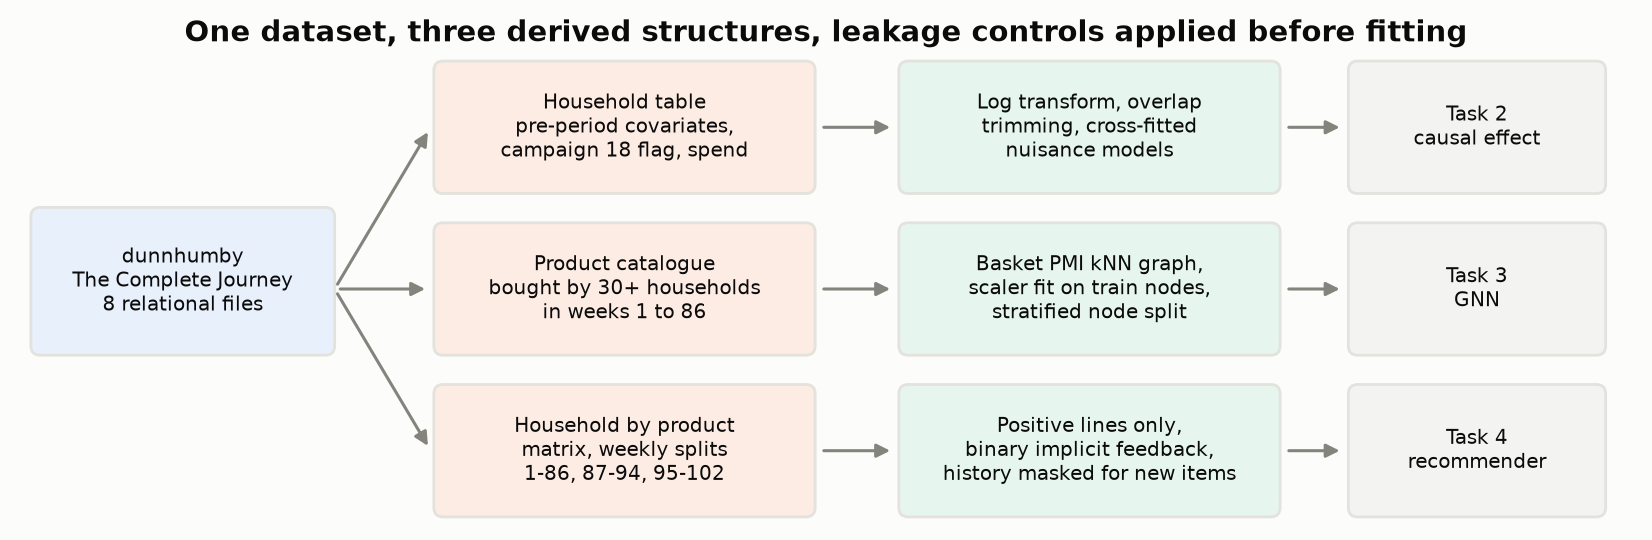

**t1_timeline.png**

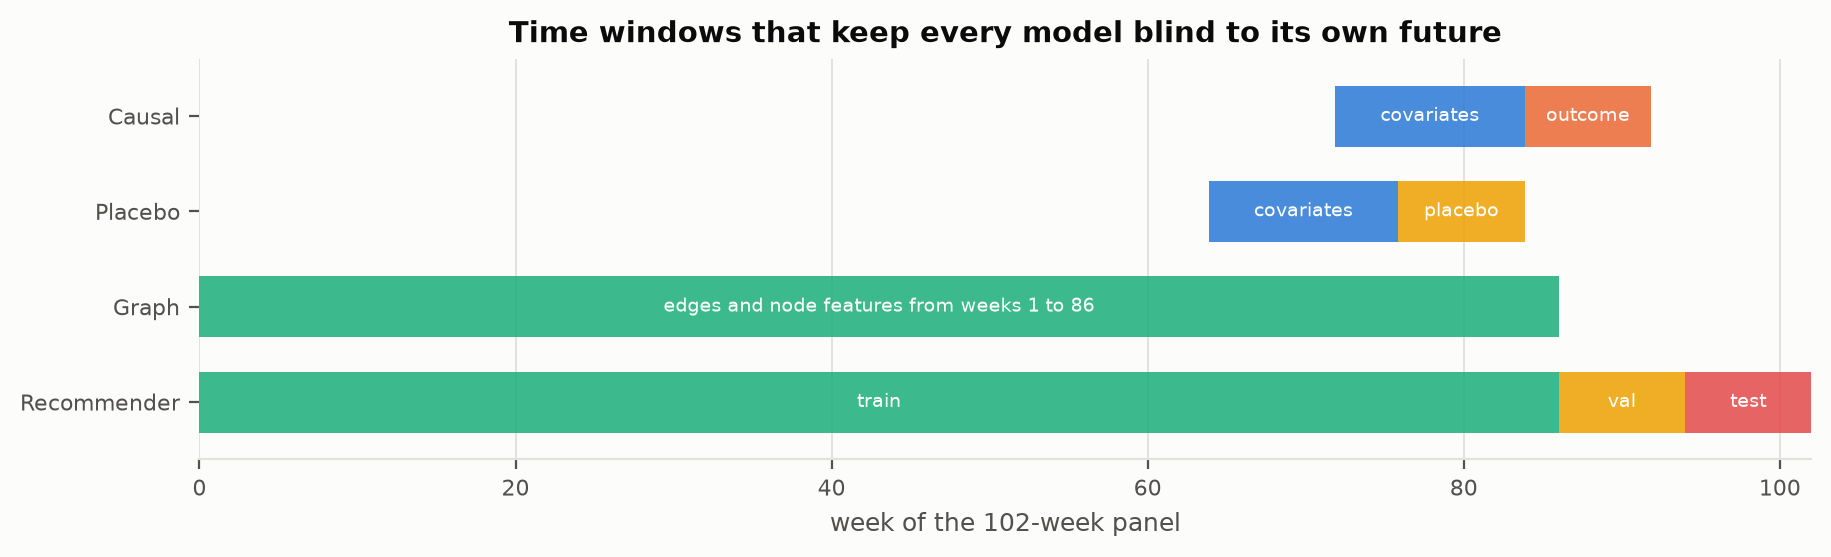

In [3]:
import task1_setup

t1, ARTEFACTS["task1"], TIMINGS["task1"] = run_task(
    "Task 1 problem definition, dataset and baselines", task1_setup.run
)


## Task 2 causal inference

Effect of TypeA campaign 18 on household spend.


### Task 2 causal inference

population
 treated                sample  households  pre_spend  pre_baskets  hist_spend  prior_type_a  prior_campaigns  concurrent_campaigns  out_spend  out_baskets  out_promoted_spend  out_coupon_cost  has_demographics
       0 all active households        1168   241.4400       8.7700   1147.7600        0.3700           0.8000                0.1400   180.5400       6.2000             86.8600           0.9400            0.1400
       1 all active households        1125   665.2300      22.5800   3496.6201        1.5000           3.4600                1.0500   473.9900      14.8100            218.7900           3.2300            0.5700
       0    overlap population         821   276.1300      10.1000   1342.6801        0.4900           1.0200                0.1500   201.6400       7.0000             98.0900           1.0900            0.1800
       1    overlap population         900   508.2500      17.3400   2674.5400        1.4000           2.9400                0.7600   369.6100   

*Task 2 causal inference finished in 54 s and wrote 11 tables and 6 figures.*

**t2_balance.csv**

,covariate,raw_all,raw,ipw,overlap,matched,raw_all_abs,raw_abs,ipw_abs,overlap_abs,matched_abs
0,pre_spend,1.1972,0.7883,-0.1029,0.0009,0.0364,1.1972,0.7883,0.1029,0.0009,0.0364
1,pre_baskets,1.2779,0.8507,-0.1468,0.0010,-0.0709,1.2779,0.8507,0.1468,0.0010,0.0709
2,pre_recency,-0.7596,-0.4705,0.0633,0.0001,0.0327,0.7596,0.4705,0.0633,0.0001,0.0327
3,pre_products,1.1569,0.7443,-0.1043,-0.0010,0.0032,1.1569,0.7443,0.1043,0.0010,0.0032
4,pre_commodities,1.1229,0.7152,-0.0888,0.0015,-0.0185,1.1229,0.7152,0.0888,0.0015,0.0185
5,pre_stores,0.5289,0.3269,-0.0837,-0.0004,-0.0149,0.5289,0.3269,0.0837,0.0004,0.0149
6,pre_discount_share,-0.1398,-0.1023,0.0782,-0.0003,0.0629,0.1398,0.1023,0.0782,0.0003,0.0629
7,pre_coupon_lines,0.6532,0.4027,-0.0449,-0.0003,0.0806,0.6532,0.4027,0.0449,0.0003,0.0806
8,pre_basket_value,0.3497,0.2015,0.0065,-0.0007,0.1317,0.3497,0.2015,0.0065,0.0007,0.1317
9,pre_private_share,0.0306,0.0549,0.0140,-0.0004,-0.0002,0.0306,0.0549,0.0140,0.0004,0.0002


**t2_confounder_sets.csv**

... (16 outputs left out)

,benchmark,multiple,r2_treatment,r2_outcome,adjusted_estimate
0,pre_spend,1,0.0001,0.0339,-4.2312
1,pre_spend,2,0.0002,0.0677,-3.4151
2,pre_spend,3,0.0003,0.1016,-2.5990
3,pre_baskets,1,0.0000,0.0476,-4.7361
4,pre_baskets,2,0.0000,0.0953,-4.4250
5,pre_baskets,3,0.0000,0.1429,-4.1139
6,pre_recency,1,0.0004,0.0047,-4.3978
7,pre_recency,2,0.0008,0.0093,-3.7482
8,pre_recency,3,0.0012,0.0140,-3.0984
9,pre_products,1,0.0007,0.0063,-4.0528


**t2_trimming.csv**

,trim,households,treated,ipw_att,aipw_att,aipw_att_se
0,0.0000,2293,1125,-276.0582,-262.2573,291.5747
1,0.0100,2170,1101,-215.6153,-71.8119,140.7909
2,0.0250,1982,1019,-89.6033,-25.5432,65.2152
3,0.0500,1721,900,-21.8087,2.4791,33.2698
4,0.1000,1304,713,7.1395,-7.8586,35.0443


**t2_balance.png**

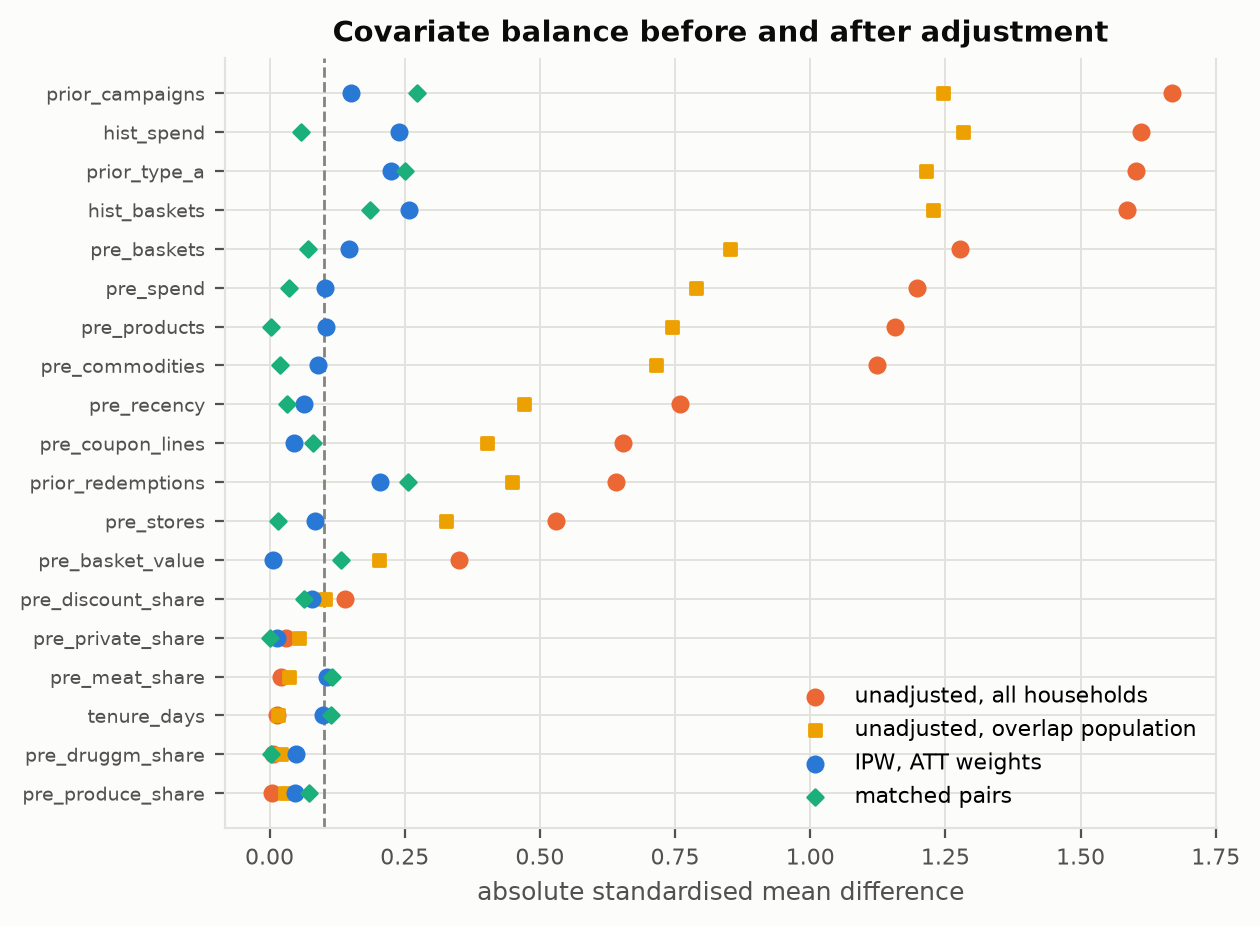

**t2_dag.png**

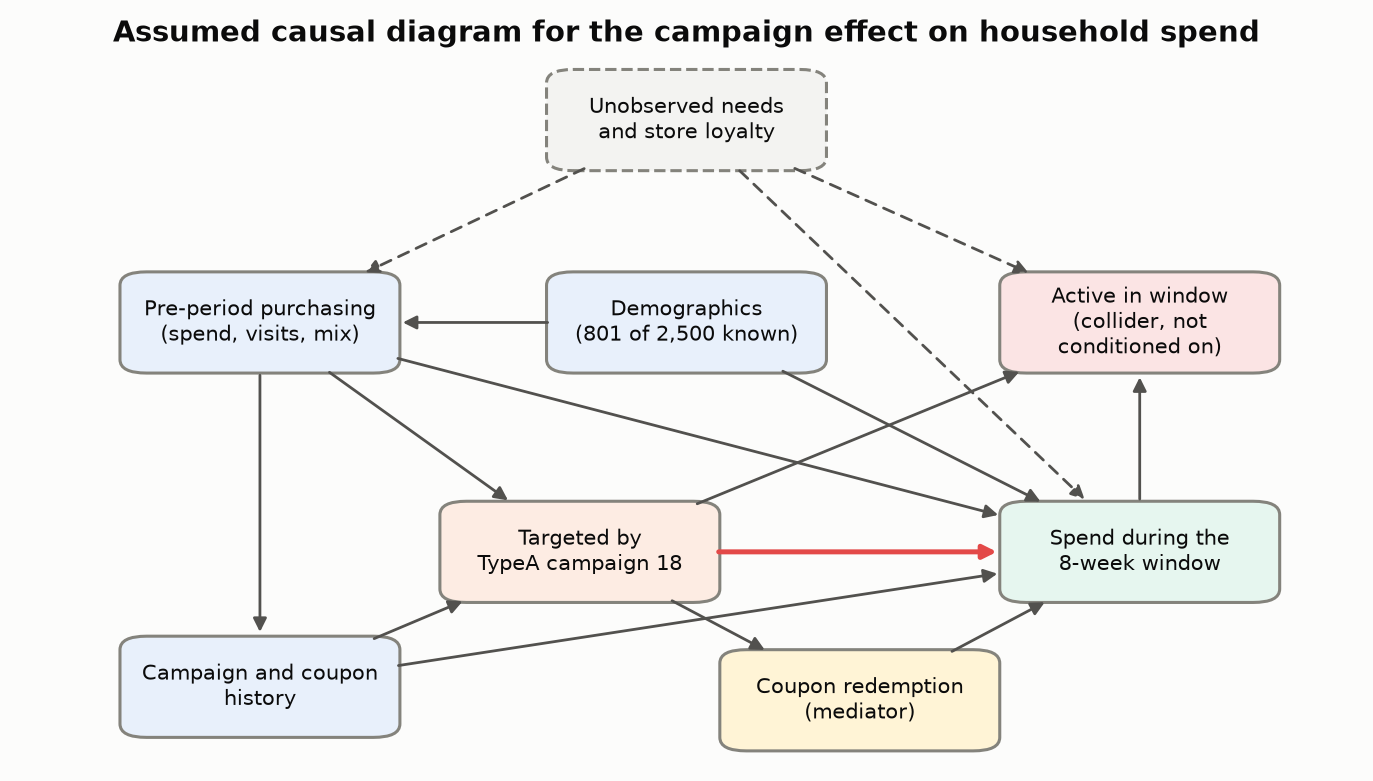

**t2_estimates.png**

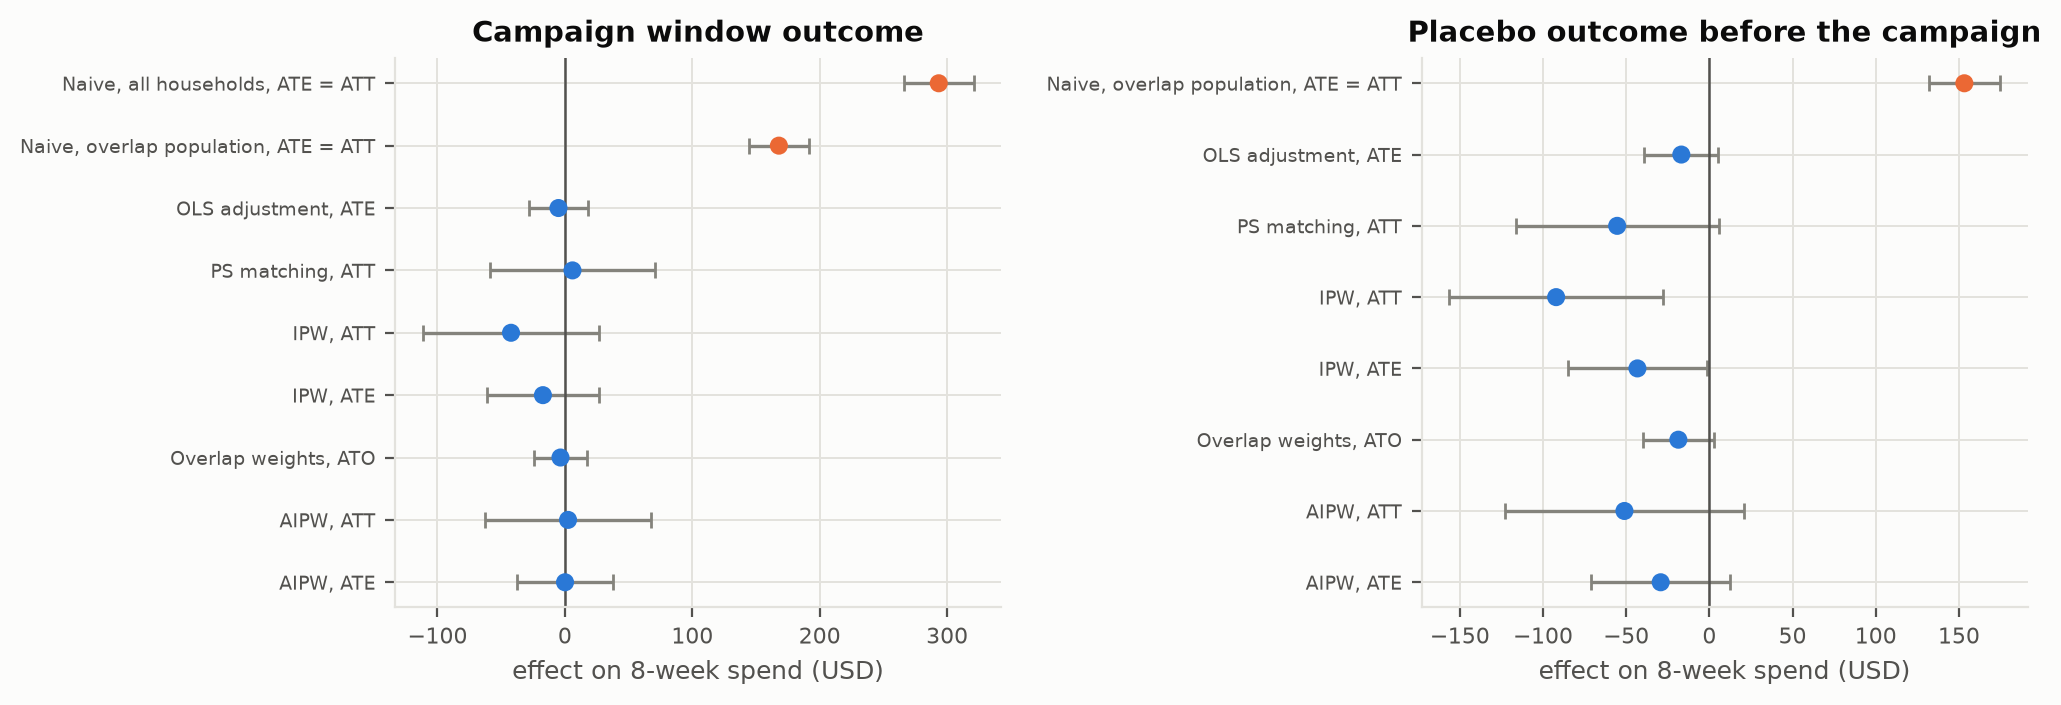

**t2_heterogeneity.png**

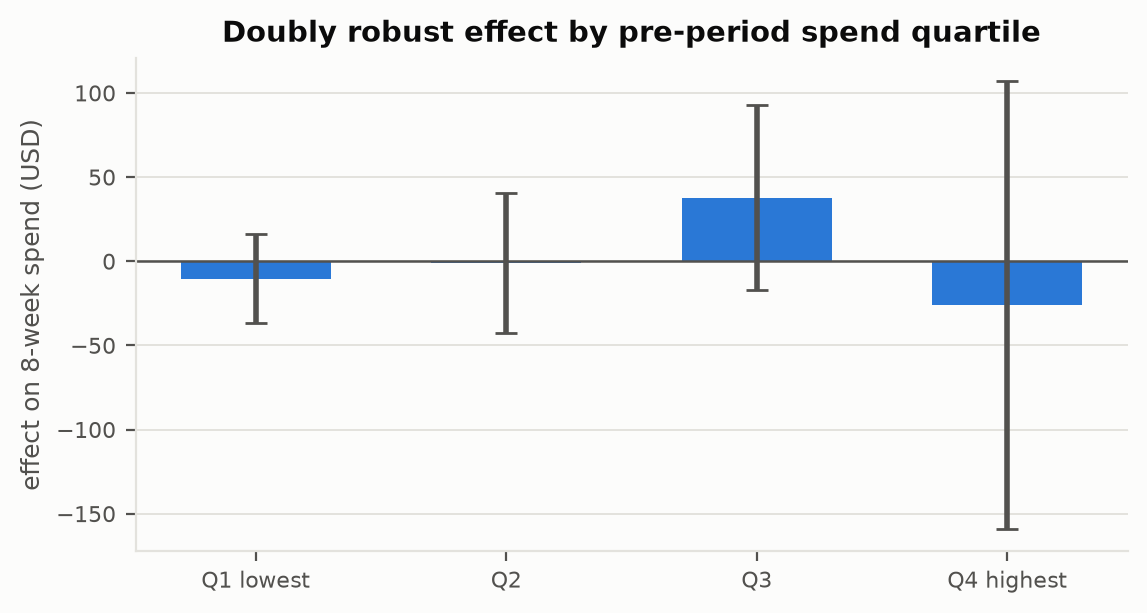

**t2_overlap.png**

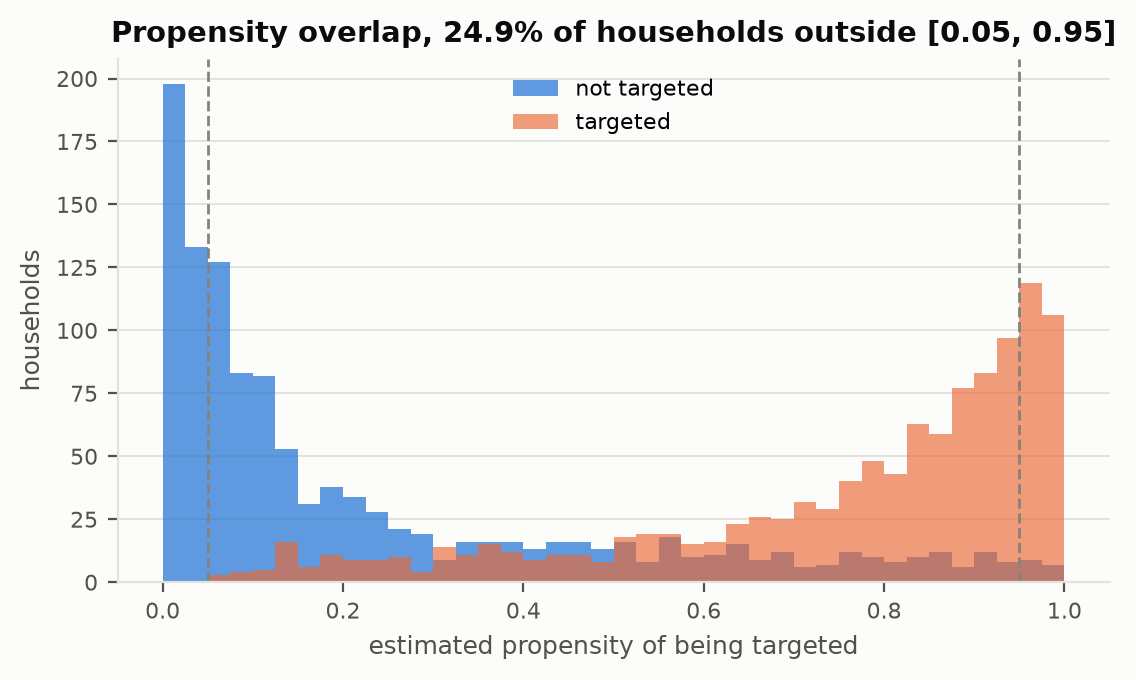

**t2_sensitivity.png**

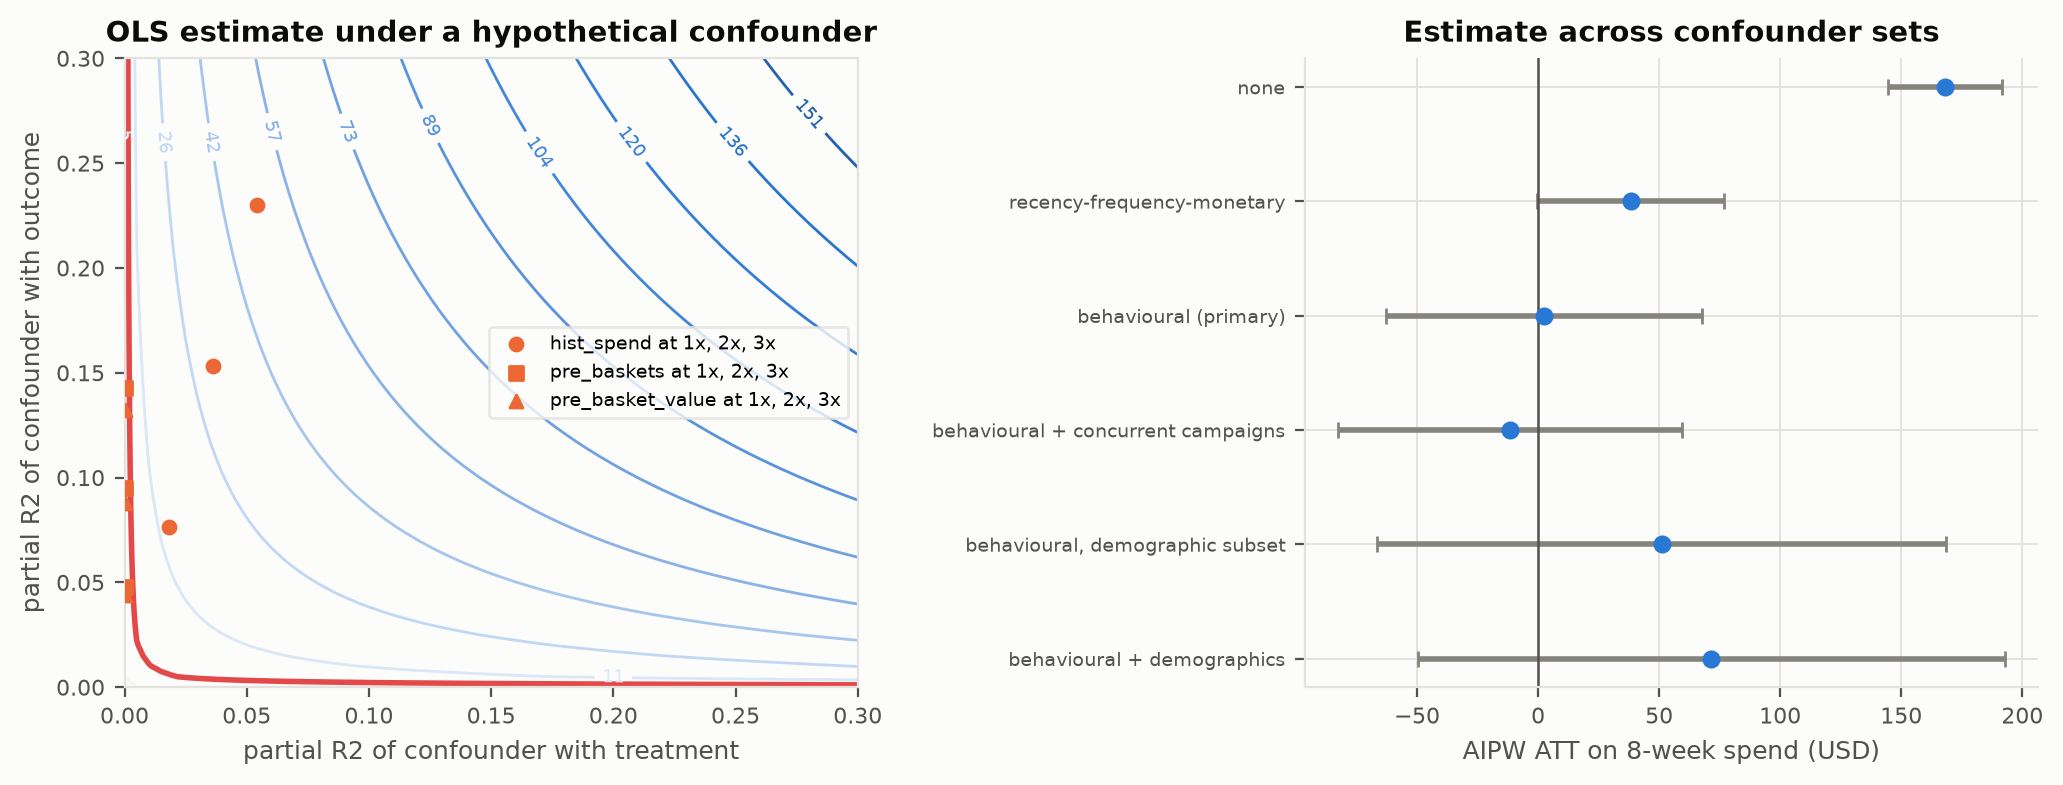

In [4]:
import task2_causal

t2, ARTEFACTS["task2"], TIMINGS["task2"] = run_task(
    "Task 2 causal inference", task2_causal.run
)


## Task 3 graph neural networks

Department classification on the basket co-purchase graph.


### Task 3 graph neural networks

graph statistics
 nodes  undirected_edges  density  mean_degree  median_degree  max_degree  isolated_nodes  components  giant_component_share  edge_homophily_department  edge_homophily_labelled  class_insensitive_homophily  k
  9661             21905   0.0005       4.5347         4.0000          44               8          12                 0.9977                     0.7473                   0.7551                       0.3327  3
  9661             35579   0.0008       7.3655         6.0000          68               8          10                 0.9986                     0.7196                   0.7276                       0.2758  5
  9661             69077   0.0015      14.3002        12.0000         185               8           9                 0.9992                     0.6834                   0.6909                       0.2052 10
  9661            133965   0.0029      27.7332        21.0000         666               8           9                 0.9992                     0.

*Task 3 graph neural networks finished in 589 s and wrote 9 tables and 5 figures.*

**t3_aggregation.csv**

,aggregation,accuracy_mean,balanced_accuracy_mean,macro_f1_mean,weighted_f1_mean,train_seconds_mean,accuracy_std,balanced_accuracy_std,macro_f1_std,weighted_f1_std,train_seconds_std
0,mean,0.7506,0.6909,0.5510,0.7779,2.8837,0.0220,0.0340,0.0042,0.0216,1.0098
1,max,0.7113,0.6523,0.5084,0.7402,3.0305,0.0277,0.0121,0.0278,0.0216,0.7513
2,sum,0.7130,0.6210,0.4826,0.7448,2.3365,0.0175,0.0181,0.0171,0.0158,0.6610


**t3_classes.csv**

... (12 outputs left out)

,model,seed,accuracy,balanced_accuracy,macro_f1,weighted_f1,f1_grocery,f1_drug_gm,f1_meat_pckgd,f1_produce,f1_meat,f1_deli,f1_pastry,f1_nutrition,f1_seafood_pckgd,val_macro_f1,best_epoch,epochs,train_seconds,seconds_per_epoch,infer_seconds,parameters
0,Logistic regression,25941494,0.5298,0.6619,0.3958,0.5900,0.6451,0.4912,0.3866,0.3887,0.7563,0.3206,0.2794,0.1047,0.1895,0.4003,1,1,0.1542,0.1542,0.0000,288
1,MLP,25941494,0.6061,0.6827,0.4508,0.6560,0.7151,0.5680,0.3750,0.5158,0.7200,0.4800,0.2667,0.2162,0.2000,0.4543,91,131,0.6381,0.0049,0.0002,5257
2,Label propagation,25941494,0.7440,0.1210,0.1129,0.6415,0.8519,0.1639,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.1172,30,30,0.2765,0.0092,0.2765,0
3,GCN,25941494,0.5287,0.6078,0.3657,0.5873,0.6381,0.5991,0.3316,0.5392,0.3770,0.3768,0.1655,0.1573,0.1069,0.3782,65,105,2.0147,0.0192,0.0050,5257
4,GraphSAGE,25941494,0.7309,0.7270,0.5490,0.7581,0.8227,0.6418,0.4985,0.5930,0.7611,0.6122,0.2927,0.3509,0.3684,0.5625,99,139,1.8919,0.0136,0.0028,10377
5,GAT,25941494,0.5084,0.5844,0.3560,0.5636,0.6148,0.5937,0.3370,0.3684,0.3868,0.4444,0.1556,0.1798,0.1235,0.3855,93,133,4.4052,0.0331,0.0082,5531
6,Logistic regression,42,0.5460,0.6519,0.3966,0.6080,0.6670,0.5312,0.3333,0.4262,0.7818,0.2839,0.2542,0.1314,0.1607,0.3877,1,1,0.1889,0.1889,0.0000,288
7,MLP,42,0.6186,0.6767,0.4525,0.6688,0.7275,0.6056,0.3862,0.5164,0.7568,0.4561,0.1899,0.1918,0.2424,0.4590,101,141,0.8125,0.0058,0.0006,5257
8,Label propagation,42,0.7450,0.1223,0.1150,0.6436,0.8524,0.1828,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.1206,30,30,0.0399,0.0013,0.0399,0
9,GCN,42,0.5888,0.5886,0.3887,0.6438,0.7069,0.6161,0.3608,0.5505,0.4224,0.4182,0.1677,0.1556,0.1000,0.3869,128,168,3.6534,0.0217,0.0101,5257


**t3_robustness.csv**

,model,perturbation,level,accuracy_mean,balanced_accuracy_mean,macro_f1_mean,weighted_f1_mean,accuracy_std,balanced_accuracy_std,macro_f1_std,weighted_f1_std
0,GCN,drop,0.0000,0.5613,0.6144,0.3808,0.6203,0.0304,0.0296,0.0130,0.0294
1,GCN,drop,0.2500,0.5670,0.6021,0.3869,0.6244,0.0141,0.0244,0.0147,0.0138
2,GCN,drop,0.5000,0.5509,0.5820,0.3676,0.6078,0.0310,0.0293,0.0043,0.0315
3,GCN,drop,0.7500,0.5223,0.5353,0.3436,0.5836,0.0195,0.0348,0.0054,0.0215
4,GCN,drop,0.9000,0.5132,0.5378,0.3436,0.5770,0.0057,0.0299,0.0112,0.0038
5,GCN,noise,0.0000,0.5613,0.6144,0.3808,0.6203,0.0304,0.0296,0.0130,0.0294
6,GCN,noise,0.2500,0.5280,0.5872,0.3604,0.5925,0.0366,0.0195,0.0144,0.0333
7,GCN,noise,0.5000,0.4878,0.5660,0.3365,0.5545,0.0295,0.0268,0.0100,0.0311
8,GCN,noise,1.0000,0.4760,0.5328,0.3239,0.5411,0.0242,0.0171,0.0047,0.0231
9,GCN,noise,2.0000,0.4206,0.4914,0.2880,0.4970,0.0167,0.0205,0.0074,0.0164


**t3_degree.png**

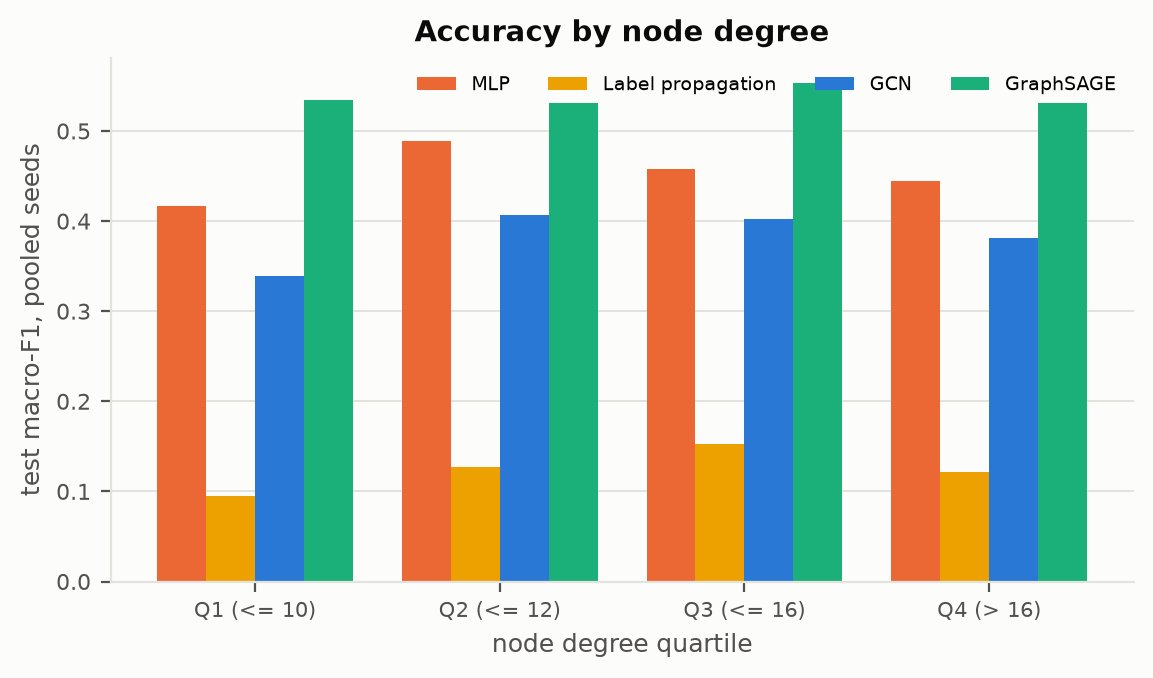

**t3_density.png**

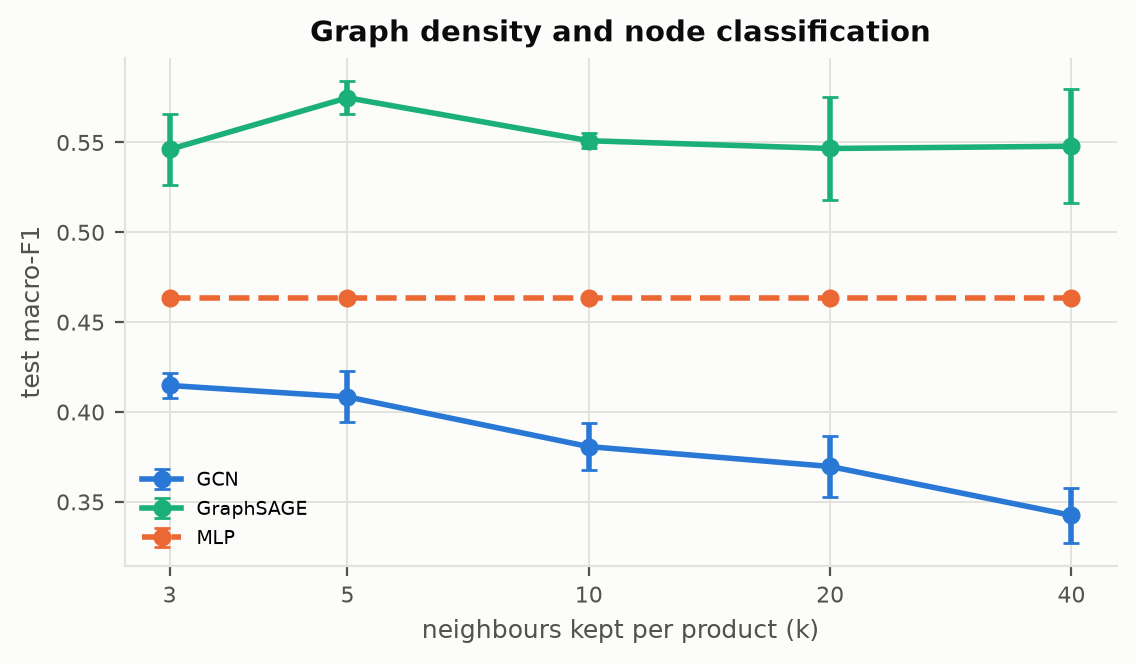

**t3_depth.png**

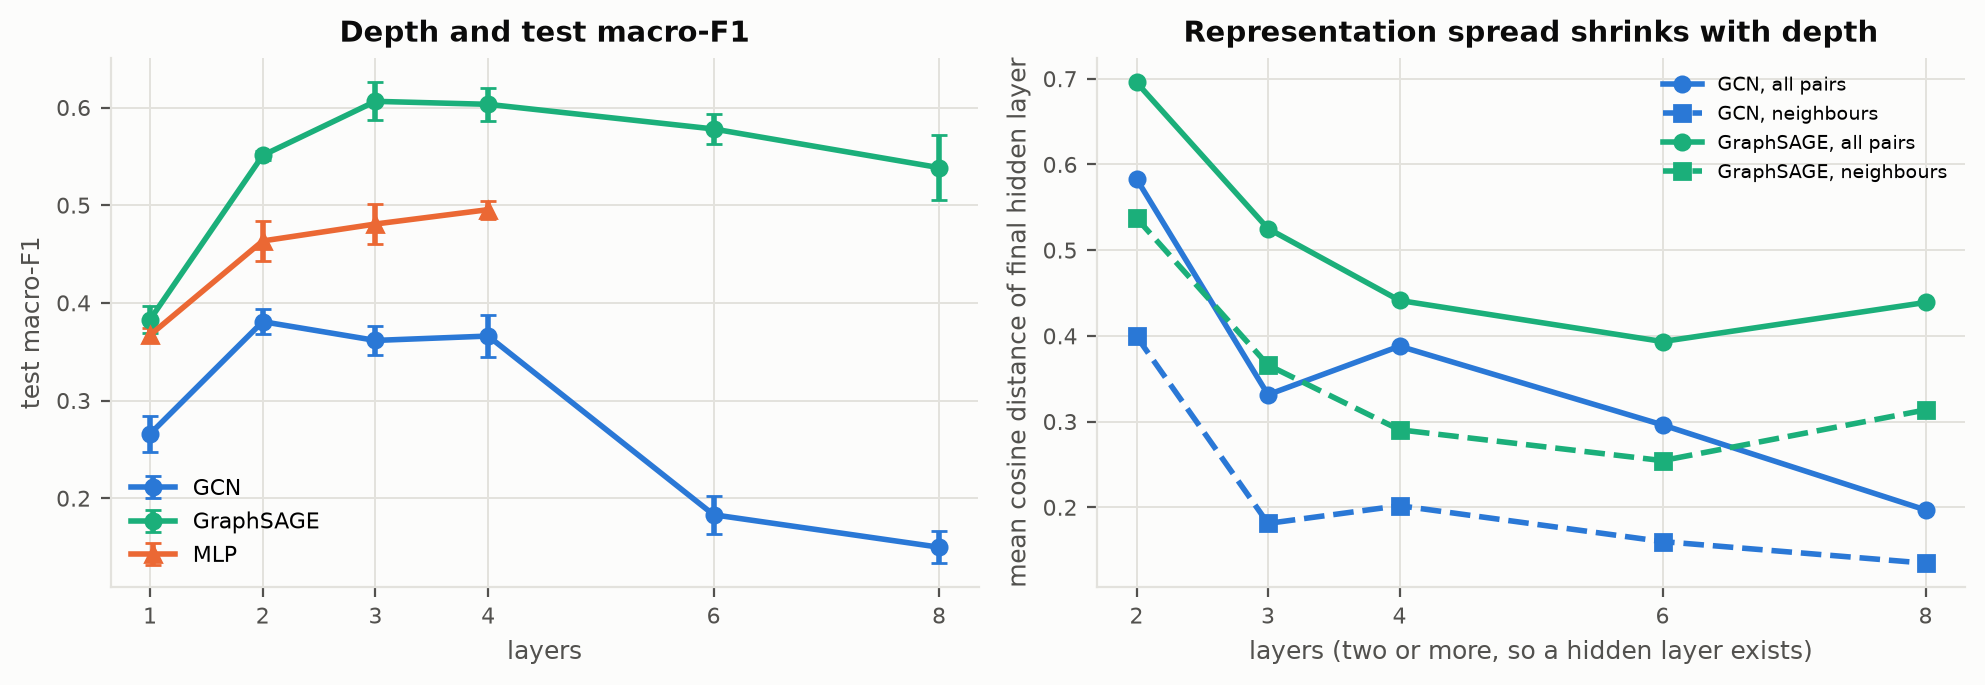

**t3_model_comparison.png**

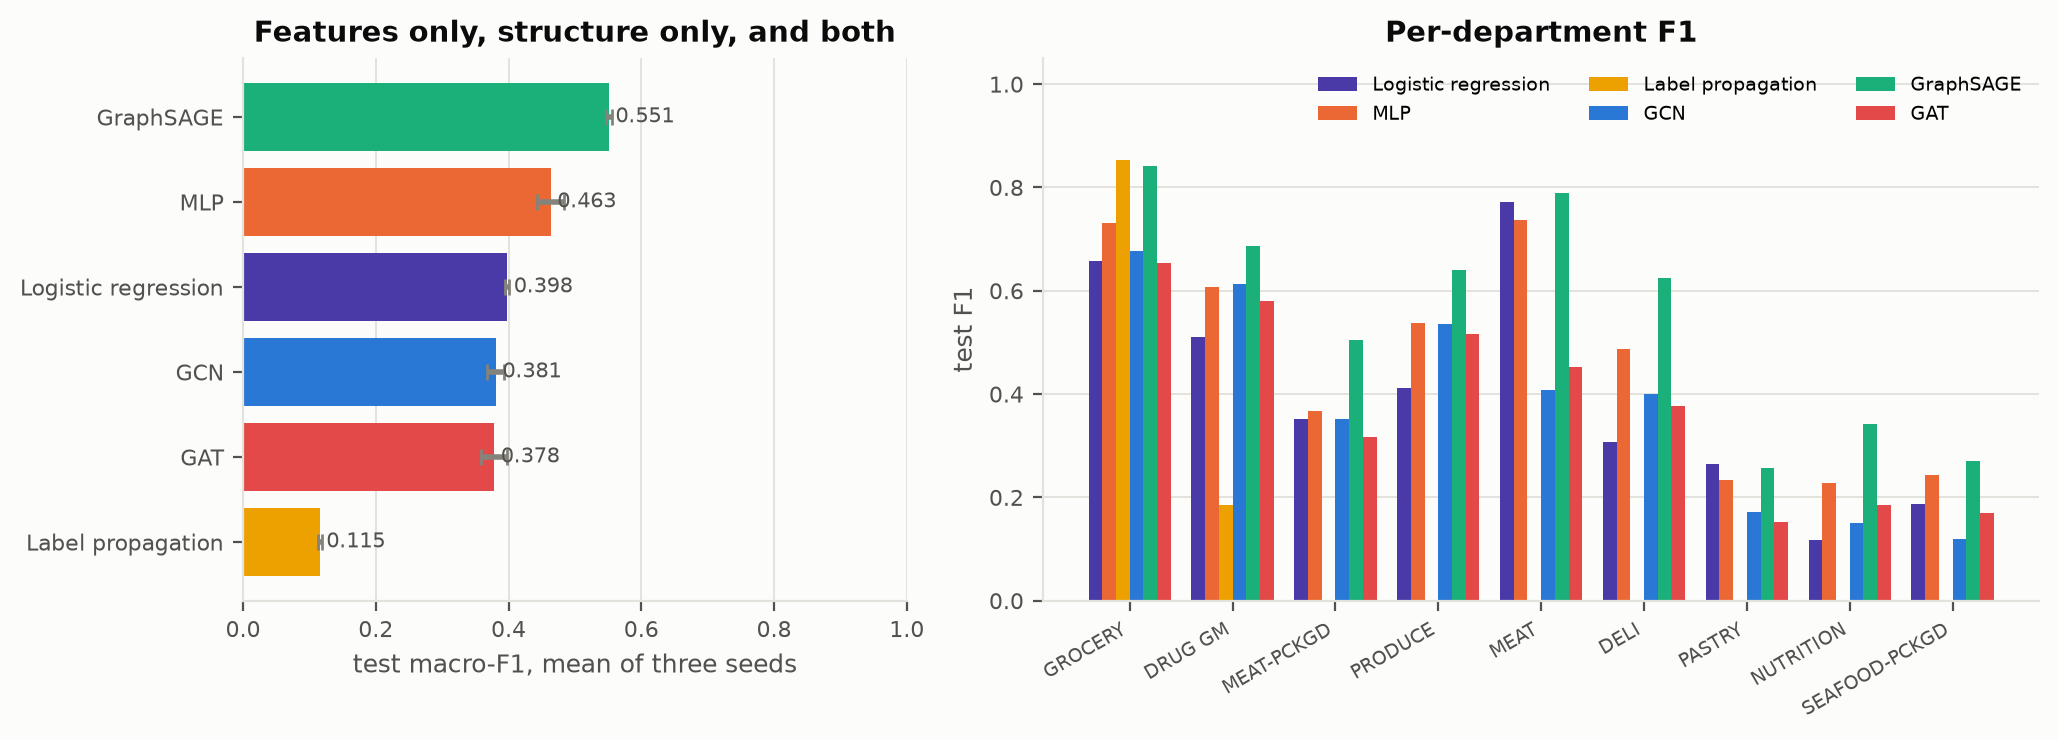

**t3_robustness.png**

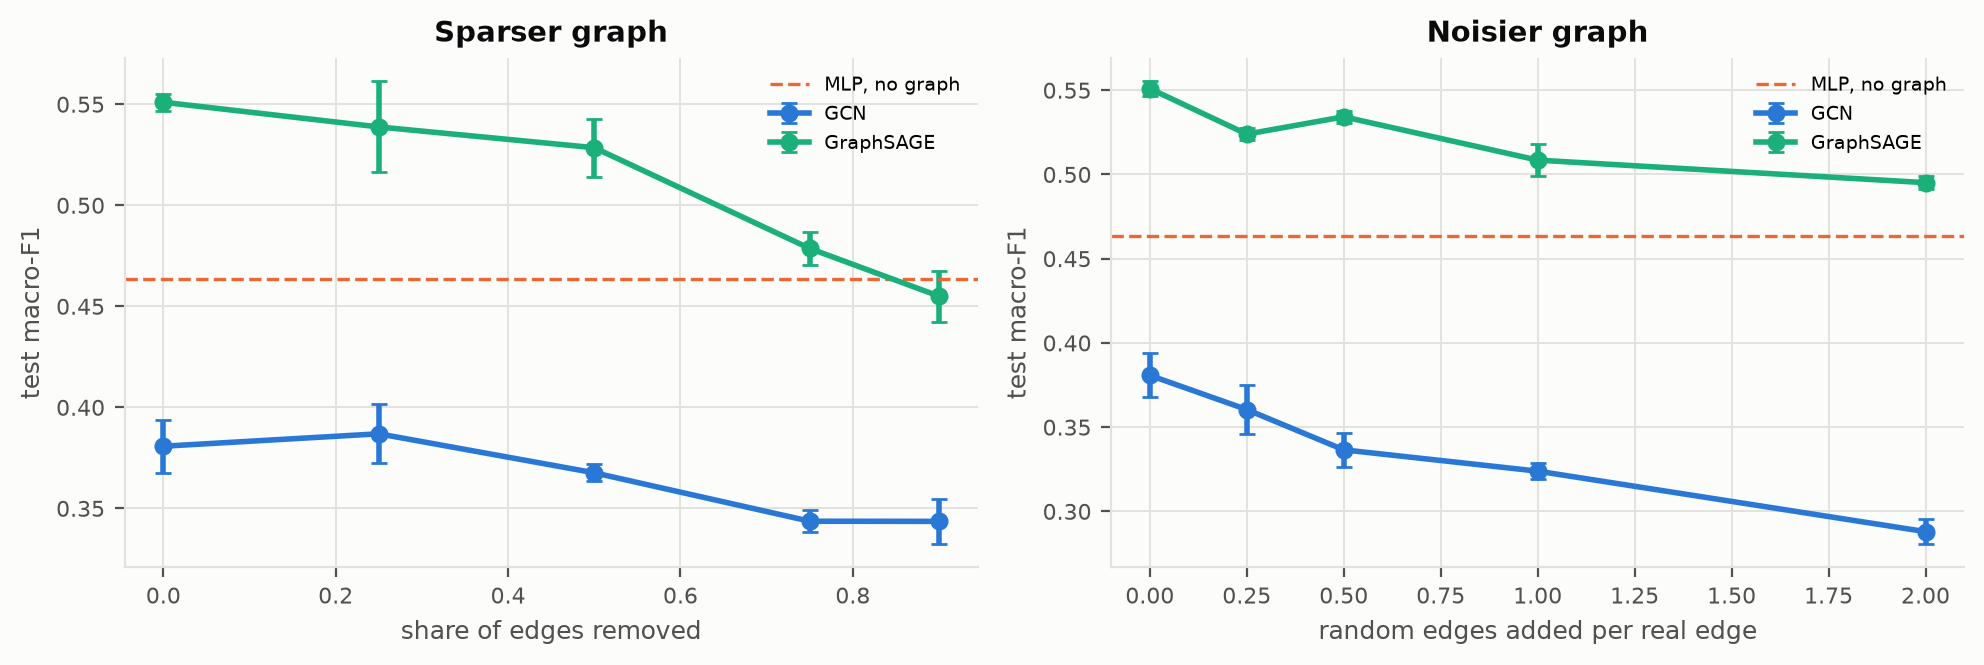

In [5]:
import task3_gnn

t3, ARTEFACTS["task3"], TIMINGS["task3"] = run_task(
    "Task 3 graph neural networks", task3_gnn.run
)


## Task 4 recommender systems

Next-period product recommendation with a temporal split.


### Task 4 recommender systems

split statistics
                            0
households          2500.0000
items               9661.0000
train_pairs       843339.0000
train_full_pairs  909535.0000
val_pairs         133671.0000
test_pairs        130227.0000
train_density          0.0377
val_users           2194.0000
test_users          2168.0000
test_repeat_share      0.5288
median_history       334.5000

selected epochs {'BPR-MF': 2, 'LightGCN': 14, 'LightGCN + IPS': 12}

                    model  protocol  precision@10_mean  recall@10_mean  ndcg@10_mean  map@10_mean  recall@20_mean  ndcg@20_mean  coverage@10_mean  novelty@10_mean  diversity@10_mean  mailer_rate@10_mean  ips_recall@10_mean  fit_seconds_mean
               Popularity all items             0.1813          0.0416        0.2363       0.1284          0.0631        0.2036            0.0010           0.5595             0.7000               0.2077              0.0157            0.0148
               Popularity new items             0.0436          0.0183 

*Task 4 recommender systems finished in 174 s and wrote 7 tables and 4 figures.*

**t4_coldstart.csv**

,model,protocol,bucket,users,recall@10
0,Popularity,all items,<= 183,543,0.0538
1,Popularity,all items,183 to 334,541,0.0423
2,Popularity,all items,334 to 555,544,0.0417
3,Popularity,all items,> 555,540,0.0287
4,Popularity,new items,<= 183,517,0.0301
5,Popularity,new items,183 to 334,533,0.0192
6,Popularity,new items,334 to 555,535,0.0138
7,Popularity,new items,> 555,537,0.0106
8,Repeat purchase,all items,<= 183,543,0.1400
9,Repeat purchase,all items,183 to 334,541,0.1114


**t4_convergence.csv**

... (8 outputs left out)

,model,epochs
0,BPR-MF,2
1,LightGCN,14
2,LightGCN + IPS,12


**t4_split_statistics.csv**

,households,items,train_pairs,train_full_pairs,val_pairs,test_pairs,train_density,val_users,test_users,test_repeat_share,median_history
0,2500,9661,843339,909535,133671,130227,0.0377,2194,2168,0.5288,334.5000


**t4_coldstart.png**

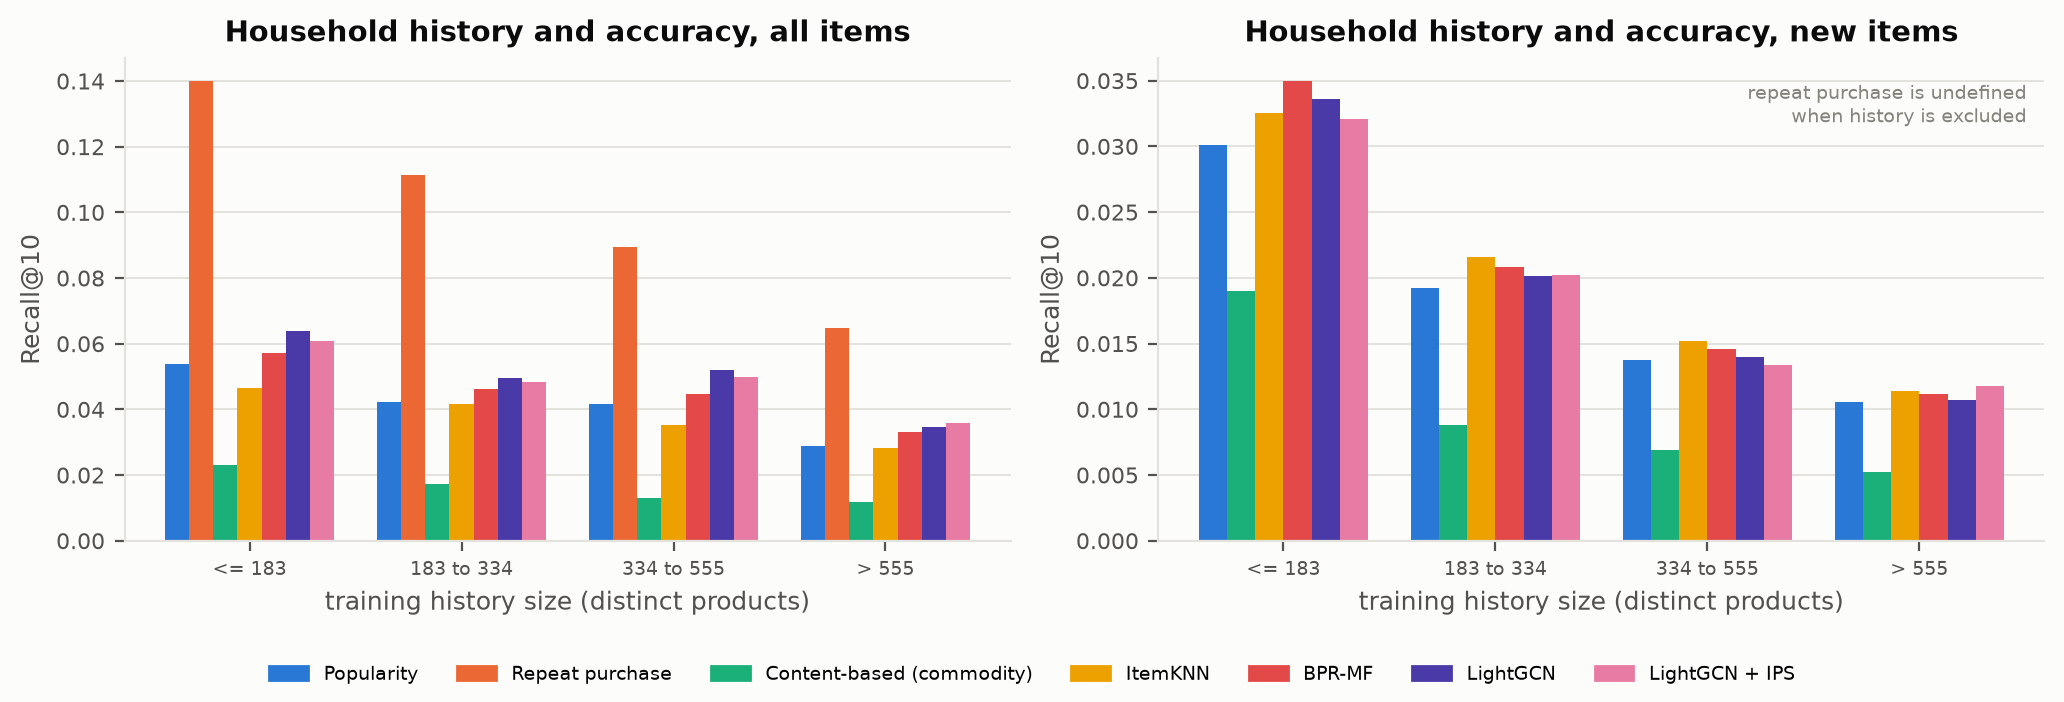

**t4_convergence.png**

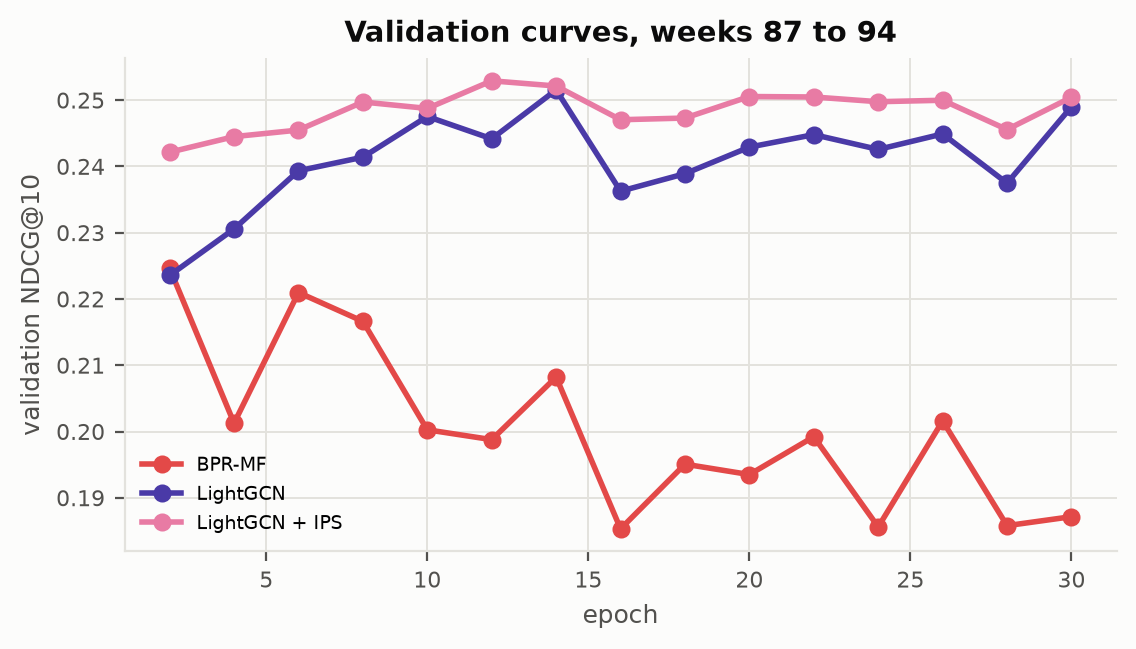

**t4_ranking.png**

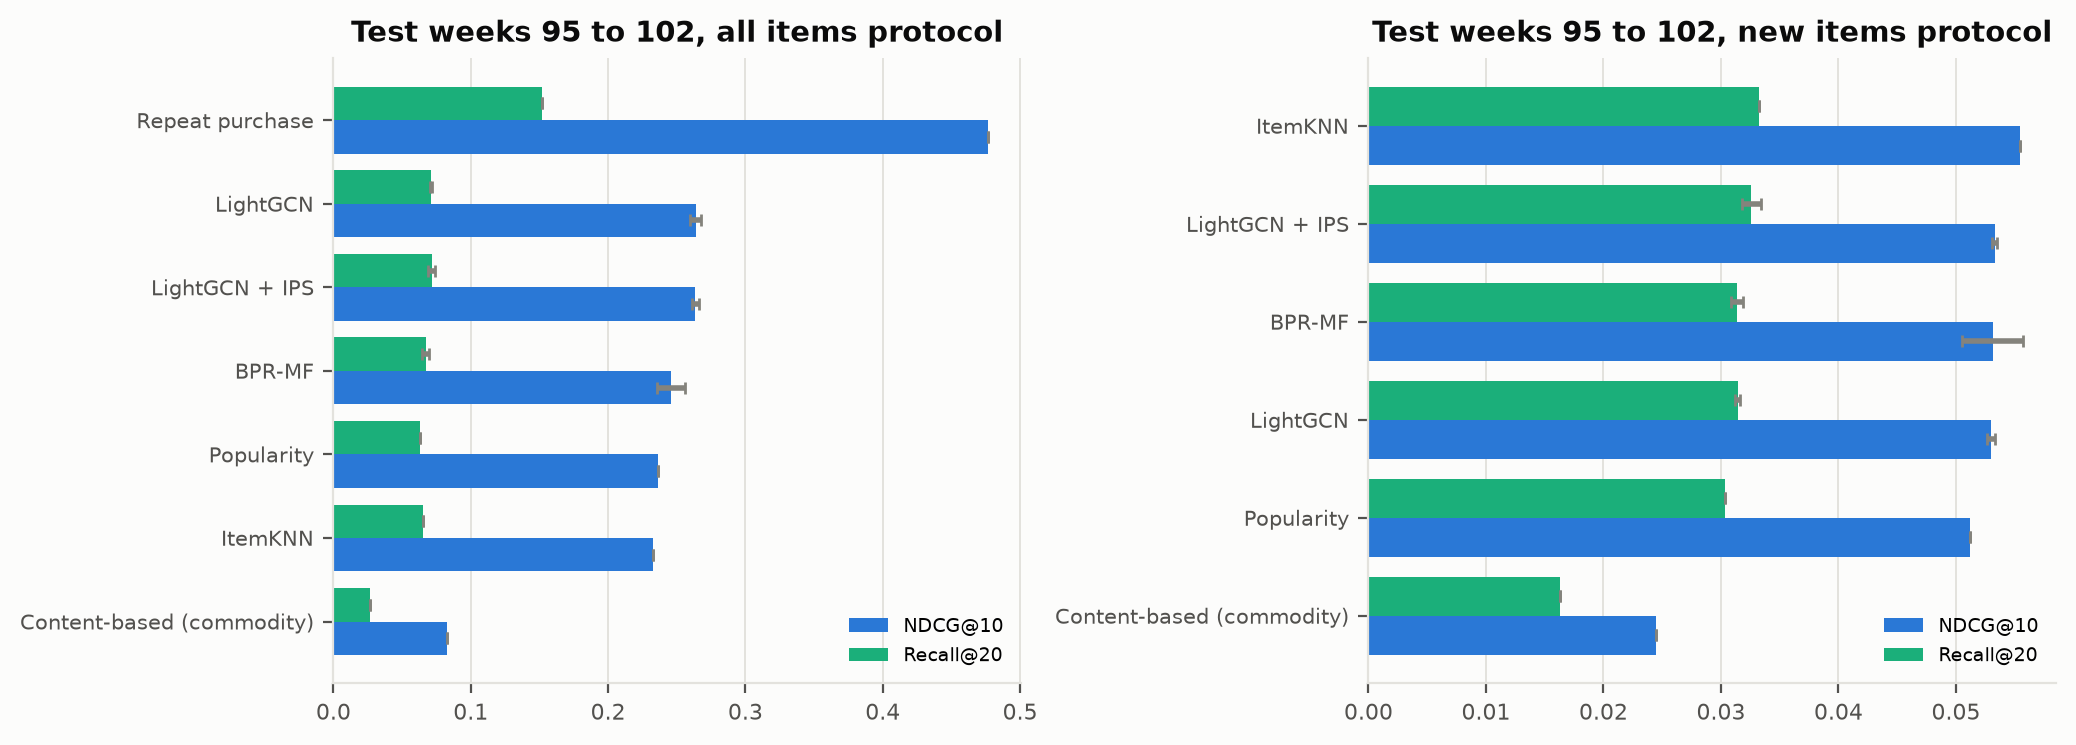

**t4_tradeoff.png**

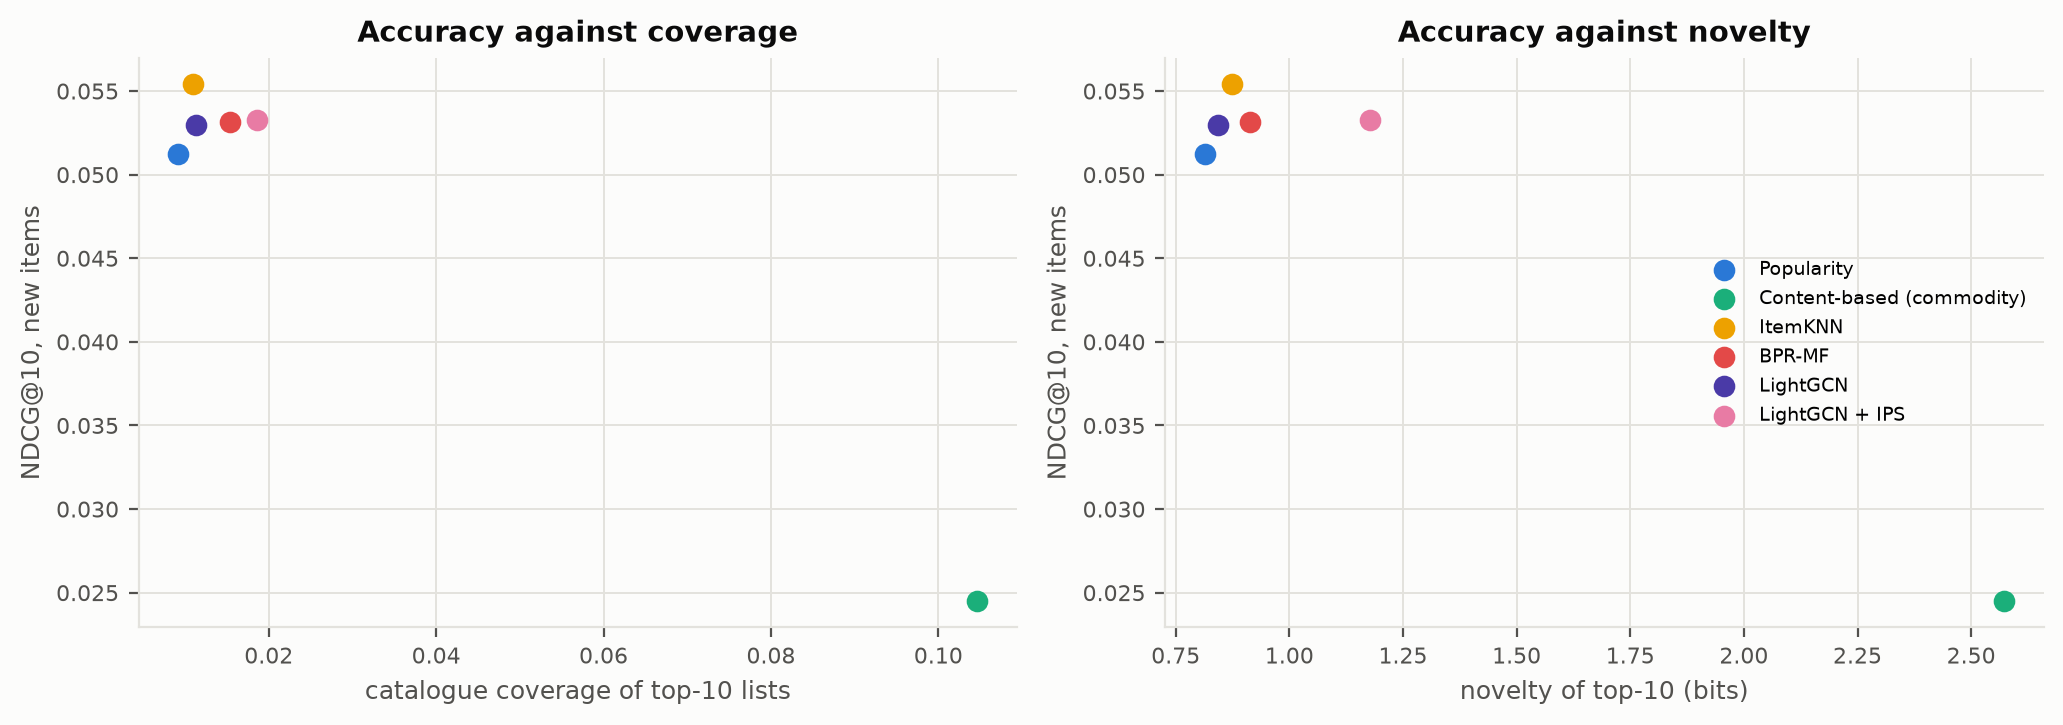

In [6]:
import task4_recsys

t4, ARTEFACTS["task4"], TIMINGS["task4"] = run_task(
    "Task 4 recommender systems", task4_recsys.run
)


## Run summary


In [7]:
summary = pd.DataFrame(
    [
        {
            "stage": stage,
            "seconds": round(TIMINGS[stage], 1),
            "tables": count_kind(ARTEFACTS[stage], CSV),
            "figures": count_kind(ARTEFACTS[stage], PNG),
        }
        for stage in ("task1", "task2", "task3", "task4")
        if stage in TIMINGS
    ]
)
display(summary)
print(f"total wall clock {summary['seconds'].sum():,.0f} s")
print()

for label, directory, pattern in (
    ("tables", config.TABLE_DIR, "*.csv"),
    ("figures", config.FIGURE_DIR, "*.png"),
    ("artefacts", config.ARTIFACT_DIR, "*"),
):
    found = sorted(directory.glob(pattern))
    print(f"{len(found)} {label} in {directory}")
    for path in found:
        print(f"  {path.name:<38} {path.stat().st_size:>10,} bytes")
    print()

,stage,seconds,tables,figures
0,task1,17.0000,3,2
1,task2,54.3000,11,6
2,task3,588.5000,9,5
3,task4,174.0000,7,4


total wall clock 834 s

30 tables in C:\Users\hp\OneDrive\SLIIT\IT6062\Assignment2\results\tables
  t1_baselines.csv                              531 bytes
  t1_data_quality.csv                           405 bytes
  t1_dataset_summary.csv                        614 bytes
  t2_balance.csv                              1,757 bytes
  t2_confounder_sets.csv                        563 bytes
  t2_estimates.csv                            2,387 bytes
  t2_heterogeneity.csv                          233 bytes
  t2_overlap.csv                                398 bytes
  t2_placebo.csv                                627 bytes
  t2_population.csv                             643 bytes
  t2_practical.csv                              421 bytes
  t2_sensitivity.csv                            142 bytes
  t2_sensitivity_benchmarks.csv               2,317 bytes
  t2_trimming.csv                               272 bytes
  t3_aggregation.csv                            408 bytes
  t3_classes.csv                

## Run log

Writes the captured stage transcript and timings to
`results/artifacts/run_all_log_.txt`


In [8]:
log_path = config.ARTIFACT_DIR / "run_all_log_.txt"
total = sum(TIMINGS.values())
lines = list(TRANSCRIPT)
lines.append(f"\npipeline finished in {total:.0f} s\n")
lines.append("\nartefacts written\n")
for label, directory, pattern in (
    ("tables", config.TABLE_DIR, "*.csv"),
    ("figures", config.FIGURE_DIR, "*.png"),
    ("artefacts", config.ARTIFACT_DIR, "*"),
):
    found = sorted(directory.glob(pattern))
    lines.append(f"  {len(found)} {label}\n")
    for path in found:
        lines.append(f"    {path.name:<40} {path.stat().st_size:>12,} bytes\n")

log_path.write_text("".join(lines), encoding="utf-8")
print(f"wrote {log_path}")
print(f"{log_path.stat().st_size:,} bytes covering {len(TIMINGS)} stages"
      f" and {total:.0f} s of wall clock")

wrote C:\Users\hp\OneDrive\SLIIT\IT6062\Assignment2\results\artifacts\run_all_log_.txt
30,848 bytes covering 4 stages and 834 s of wall clock
